In [49]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
from PIL import Image
from sklearn.metrics.cluster import adjusted_rand_score as ARI
import io
import pickle
col_dict = {0: 'orange', 1: 'lime', 2: 'purple', 3: 'red', 4:'yellow', 5:'black', 6:'green', 7:'pink', 8:'blue',9:'lime', 10:'sienna',11:'indigo'}

In [51]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    return col_ind

def mse(true, est):
    return np.mean((np.array(true) - np.array(est))**2)

# First Scenario

In [64]:
with open('fits_scenario1_10restarts.pkl', 'rb') as f:
   fits = pickle.load(f)

size_comm = [50,50,50]

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

theta_true = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
means_true = [[0.5, 0.5],[2.5,2.5],[-1.5,2.5]]
sigmas_true = [[[0.09, 0.001], [0.001, 0.09]], [[0.08, 0.002], [0.002, 0.09]], [[0.09, 0.003], [0.003, 0.08]]]
phi1_true = [[0.8,0.15,0.05],[0.15,0.8,0.05],[0.05,0.15,0.8]]
phi2_true =  [[0.7,0.15,0.05,0.1],[0.15,0.7,0.05,0.1],[0.05,0.15,0.7,0.1]]

results = {
    'ari': [],
    'theta': [],
    **{f'mu_{k}': [] for k in range(K)},
    **{f'sigma_{k}': [] for k in range(K)},
    'phi1': [],
    'phi2': [],
}
K=3
sed = 1
fit = fits[sed]
pred = np.argmax(fit['r'], axis=1)
perm = match_labels(np.array(labels), pred, K)

Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
phi_aligned = [phi[perm, :] for phi in fit['phi_list']]
results['ari'].append(ARI(labels, pred))
results['theta'].append(round(mse(theta_true, Theta_aligned),4))
results['phi1'].append(round(mse(phi1_true, phi_aligned[0]),4))
results['phi2'].append(round(mse(phi2_true, phi_aligned[1]),4))

for k in range(K):
    results[f'mu_{k}'].append(round(mse(means_true[k], mu_aligned[k]),4))
    results[f'sigma_{k}'].append(round(mse(sigmas_true[k], Sigma_aligned[k]),4))

### Plot

In [ ]:
sed = 1
random.seed(sed)
np.random.seed(sed)

size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.09, 0.001], [0.001, 0.09]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.002], [0.002, 0.09]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

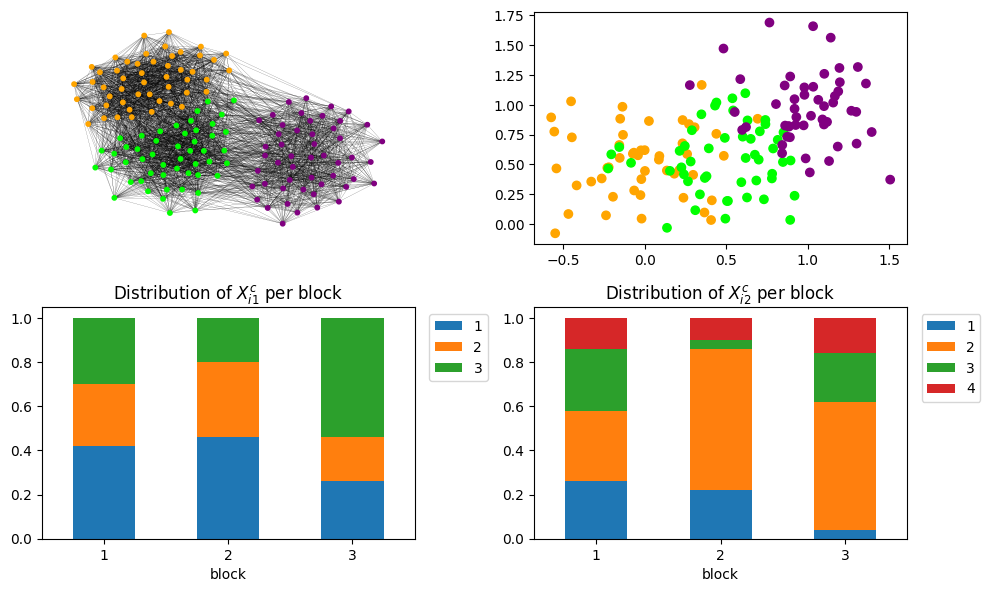

In [124]:
df = Xc.copy()
df["block"] = labels

fig, axes = plt.subplots(2,2,figsize=(10,6))
nx.draw(G, pos=nx.spring_layout(G, k=0.6,seed=6), ax=axes[0,0], node_size=10, width=0.1, node_color=dtemp['label'])
axes[0,1].scatter(dtemp.loc[:, 0], dtemp.loc[:, 1], c=dtemp['label'])

titles = [rf"$X_{{i1}}^c$", rf"$X_{{i2}}^c$"]
for i, col in enumerate(["attr_cat1", "attr_cat2"]):
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=axes[1,i])
    axes[1,i].set_title(f"Distribution of {titles[i]} per block")
    axes[1,i].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    axes[1,i].set_xticklabels([1,2,3], rotation=0)

plt.tight_layout()
plt.savefig('plot_first_2x2.png')
plt.show()

### ILouvain con Gower - first

In [ ]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [28]:
ARI(list(partition_ilouv.values()), labels)

1.0

### SA cluster first

In [9]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.6565


### STOC cluster first

In [ ]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

## Second scenario

In [ ]:
with open('fits_scenario2_10restarts.pkl', 'rb') as f:
   fits = pickle.load(f)

size_comm = [50,50,50]

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

theta_true = [[0.4, 0.2, 0.1],[0.2,0.4,0.2],[0.1,0.2,0.4]]
means_true = [[0.5, 0.5],[2.5,2.5],[-1.5,2.5]]
sigmas_true = [[[0.09, 0.001], [0.001, 0.09]], [[0.08, 0.002], [0.002, 0.09]], [[0.09, 0.003], [0.003, 0.08]]]
phi1_true = [[0.8,0.15,0.05],[0.15,0.8,0.05],[0.05,0.15,0.8]]
phi2_true =  [[0.7,0.15,0.05,0.1],[0.15,0.7,0.05,0.1],[0.05,0.15,0.7,0.1]]

K = 3
results = {
    'ari': [],
    'theta': [],
    **{f'mu_{k}': [] for k in range(K)},
    **{f'sigma_{k}': [] for k in range(K)},
    'phi1': [],
    'phi2': [],
}

sed = 0
fit = fits[sed]
pred = np.argmax(fit['r'], axis=1)
perm = match_labels(np.array(labels), pred, K)

Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
phi_aligned = [phi[perm, :] for phi in fit['phi_list']]

results['ari'].append(ARI(labels, pred))
results['theta'].append(mse(theta_true, Theta_aligned))
results['phi1'].append(mse(phi1_true, phi_aligned[0]))
results['phi2'].append(mse(phi2_true, phi_aligned[1]))

for k in range(K):
    results[f'mu_{k}'].append(mse(means_true[k], mu_aligned[k]))
    results[f'sigma_{k}'].append(mse(sigmas_true[k], Sigma_aligned[k]))

### Plot

In [118]:
sed = 0
random.seed(sed)
np.random.seed(sed)

size_comm = [50,50,50]
probs = [[0.4, 0.2, 0.1],[0.2,0.4,0.2],[0.1,0.2,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.09, 0.001], [0.001, 0.09]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.002], [0.002, 0.09]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

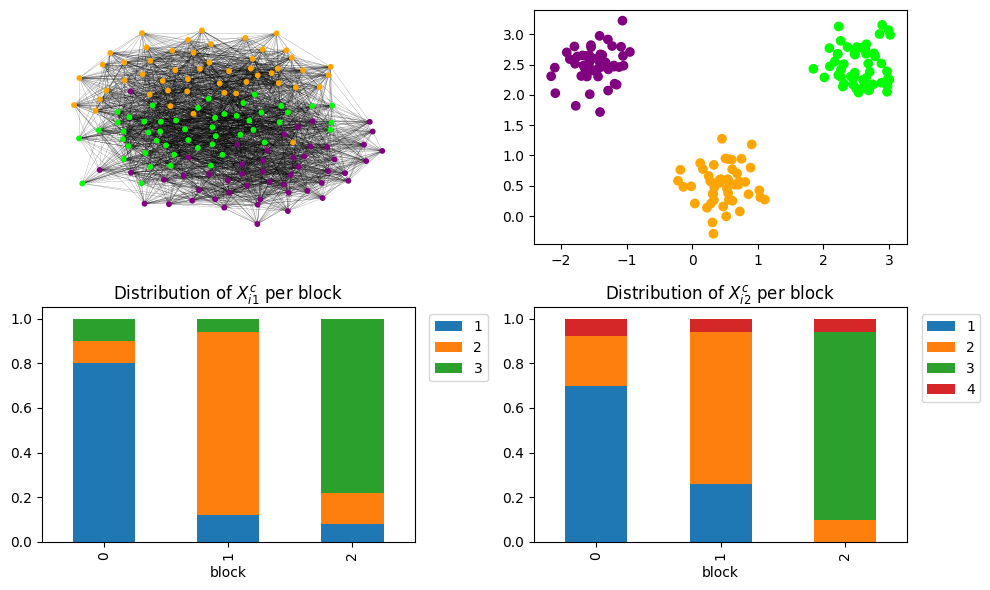

In [119]:
df = Xc.copy()
df["block"] = labels

fig, axes = plt.subplots(2,2,figsize=(10,6))
nx.draw(G, pos=nx.spring_layout(G, k=0.6,seed=6), ax=axes[0,0], node_size=10, width=0.1, node_color=dtemp['label'])
axes[0,1].scatter(dtemp.loc[:, 0], dtemp.loc[:, 1], c=dtemp['label'])

titles = [rf"$X_{{i1}}^c$", rf"$X_{{i2}}^c$"]
for i, col in enumerate(["attr_cat1", "attr_cat2"]):
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=axes[1,i])
    axes[1,i].set_title(f"Distribution of {titles[i]} per block")
    axes[1,i].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
#plt.savefig('plot_second_2x2.png')
plt.show()

### ILouvain con Gower - second

In [16]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [17]:
ARI(list(partition_ilouv.values()), labels)

0.5228988572603626

### SA cluster second

In [135]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=-0.0052


### STOC cluster second

In [ ]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

# Third scenario

In [ ]:
with open('fits_scenario3_10restarts.pkl', 'rb') as f:
   fits = pickle.load(f)

K = 3
results = {
    'ari': [],
    'theta': [],
    **{f'mu_{k}': [] for k in range(K)},
    **{f'sigma_{k}': [] for k in range(K)},
    'phi1': [],
    'phi2': [],
}

sed = 0
fit = fits[sed]
pred = np.argmax(fit['r'], axis=1)
perm = match_labels(np.array(labels), pred, K)

Theta_aligned = fit['Theta'][np.ix_(perm, perm)]
mu_aligned = [fit['mu_list'][perm[k]] for k in range(K)]
Sigma_aligned = [fit['Sigma_list'][perm[k]] for k in range(K)]
phi_aligned = [phi[perm, :] for phi in fit['phi_list']]

results['ari'].append(ARI(labels, pred))
results['theta'].append(mse(theta_true, Theta_aligned))
results['phi1'].append(mse(phi1_true, phi_aligned[0]))
results['phi2'].append(mse(phi2_true, phi_aligned[1]))

for k in range(K):
    results[f'mu_{k}'].append(mse(means_true[k], mu_aligned[k]))
    results[f'sigma_{k}'].append(mse(sigmas_true[k], Sigma_aligned[k]))

### Plot

In [120]:
sed = 0
random.seed(sed)
np.random.seed(sed)

size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0, 0.5], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.005], [0.005, 0.07]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[1, 1], cov=[[0.07, 0.001], [0.001, 0.085]], size=50)
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.33,0.33,0.34])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.5,0.15])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.15,0.5])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.25,0.25,0.25])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.6,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.7,0.15,0.1])

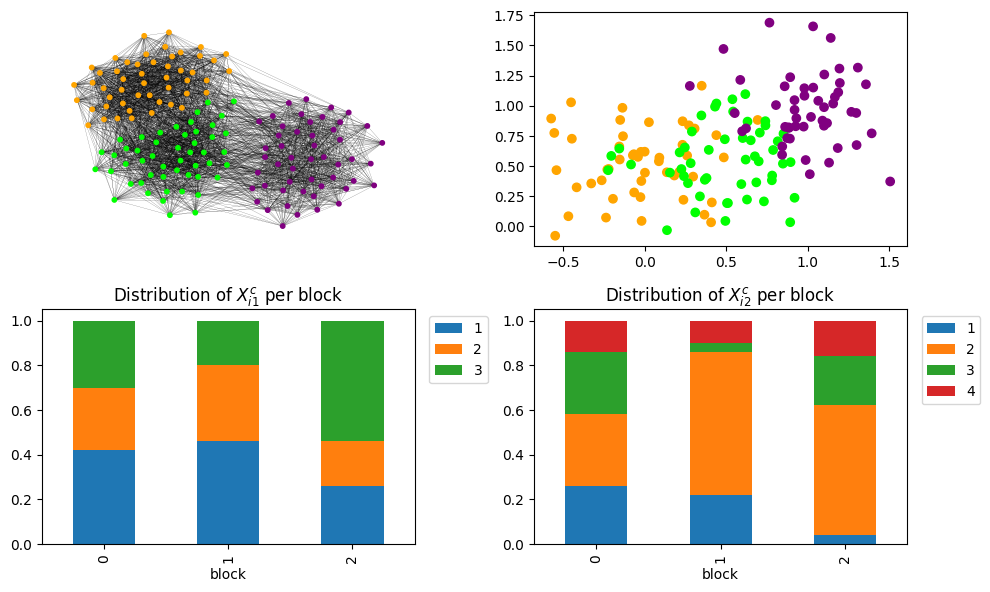

In [121]:
df = Xc.copy()
df["block"] = labels

fig, axes = plt.subplots(2,2,figsize=(10,6))
nx.draw(G, pos=nx.spring_layout(G, k=0.6,seed=6), ax=axes[0,0], node_size=10, width=0.1, node_color=dtemp['label'])
axes[0,1].scatter(dtemp.loc[:, 0], dtemp.loc[:, 1], c=dtemp['label'])

titles = [rf"$X_{{i1}}^c$", rf"$X_{{i2}}^c$"]
for i, col in enumerate(["attr_cat1", "attr_cat2"]):
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=axes[1,i])
    axes[1,i].set_title(f"Distribution of {titles[i]} per block")
    axes[1,i].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
#plt.savefig('plot_third_2x2.png')
plt.show()

### ILouvain con Gower - third

In [47]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [48]:
ARI(list(partition_ilouv.values()), labels)

1.0

### SA cluster third

In [138]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0271


### STOC cluster third

In [147]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.3878
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=11  ARI=0.2283


## Fourth scenario

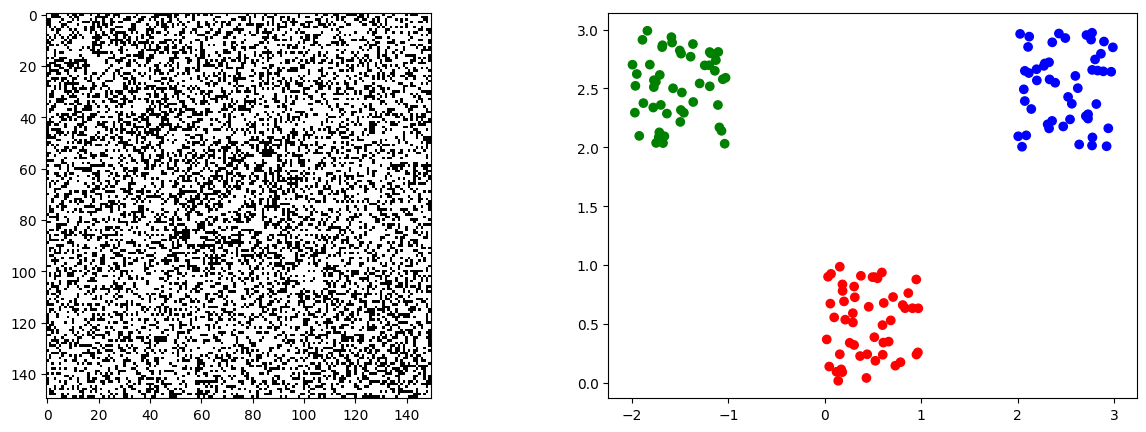

In [49]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.4, 0.3, 0.3],[0.3,0.4,0.3],[0.3,0.3,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

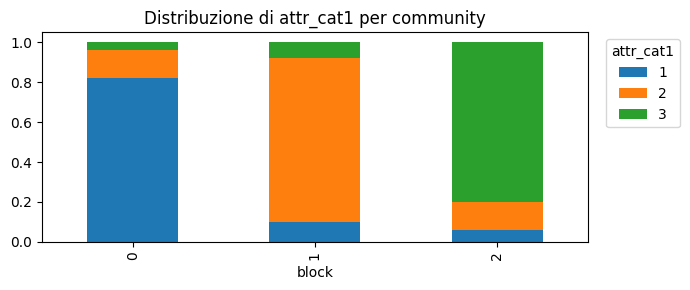

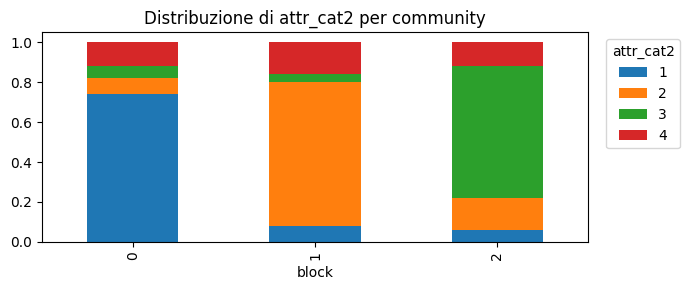

In [50]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [51]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [52]:
for K in Ks:
    print(Rs[K]['vICL'])

-7741.649757943619
-7591.971419243181
-7624.174569423979
-7666.684826878228


In [54]:
Rs[3]['Theta']

array([[0.40653061, 0.2872    , 0.316     ],
       [0.2872    , 0.38122449, 0.2996    ],
       [0.316     , 0.2996    , 0.38530612]])

In [55]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

### ILouvain con Gower - fourth

In [56]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [57]:
ARI(list(partition_ilouv.values()), labels)

0.0

### SA cluster fourth

In [156]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0133


### STOC cluster fourth

In [157]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=8  ARI=0.8175
